# Homework 1 Worked Example: Corn Production and Prices

### AGEC 370: Agricultural Price Analysis

Click the badge below to open in Google Colab:

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/chuckgrigsby0/agec_370/blob/main/code/notebooks/hw01_example_corn_production_prices.ipynb)

---

## Objective

Load U.S. corn production and price data from USDA NASS and the Consumer Price Index (CPI) data from BLS. Calculate real (inflation-adjusted) prices and create visualizations showing production, nominal prices, real prices, and year-over-year percentage changes.

---

## How to Use This Notebook

1. Save a copy of this notebook to your Google Drive.
2. Run every cell in order from top to bottom.
3. Read the comments above each step before running the code. Review the output after running code cells.
4. Open the [Homework 1 notebook](https://colab.research.google.com/github/chuckgrigsby0/agec_370/blob/main/code/notebooks/hw01_hog_production_prices.ipynb). Complete the same steps with the hog production and price data.

## Data Description

The file `corn_production_price.csv` has one row per year, 1913 to 2025.

Production is for the calendar year. The price is for the marketing year, which currently runs from September to August and is labeled by the year it starts. For example, the 2024 price is the average for September 2024 through August 2025, the months when the 2024 crop is sold.

| Column | Description | Units |
|---|---|---|
| `year` | Calendar year for production. Marketing year for price. | |
| `production_billion_bu` | U.S. corn production (USDA NASS) | Billion bushels |
| `nominal_price` | Marketing year average price received by U.S. corn producers (USDA NASS) | Dollars per bushel |
| `annual_avg_cpi` | Consumer Price Index for All Urban Consumers (CPI-U), all items, annual average (BLS) | Index (1982-84 = 100) |

## Package and Data Loading

Import necessary libraries and load the corn production and price dataset.

In [1]:
# Import data manipulation libraries
import pandas as pd
import numpy as np

# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load data from GitHub repository
base_url = "https://raw.githubusercontent.com/chuckgrigsby0/agec_370/main/data/hw/"

# pd.read_csv() reads a CSV file into a DataFrame.
# The file name is given in the Data Description above.
corn = pd.read_csv(base_url + "corn_production_price.csv")

## Data Exploration

Examine the structure and content of the data.

In [3]:
# Display column names in list format
print(f"Column names: {list(corn.columns)}")

# Display data types of each column
print(f"Data types of each column:\n{corn.dtypes}")

Column names: ['year', 'production_billion_bu', 'nominal_price', 'annual_avg_cpi']
Data types of each column:
year                       int64
production_billion_bu    float64
nominal_price            float64
annual_avg_cpi           float64
dtype: object


### Preview first/last few rows

- Use `.head()` to view the first 5 rows.
- Use `.tail()` to view the last 5 rows.

In [4]:
corn.head()

,year,production_billion_bu,nominal_price,annual_avg_cpi
0,1913,2.272540,0.659,9.9
1,1914,2.523750,0.673,10.0
2,1915,2.829044,0.651,10.1
3,1916,2.425206,1.130,10.9
4,1917,2.908242,1.390,12.8


In [5]:
corn.tail()

,year,production_billion_bu,nominal_price,annual_avg_cpi
108,2021,15.017788,6.00,270.970
109,2022,13.650531,6.54,292.655
110,2023,15.340520,4.55,304.702
111,2024,14.891756,4.24,313.689
112,2025,16.963628,4.16,321.943


### Obtain basic summary statistics of the data

We can use the `describe()` method to generate several summary statistics. Note that `np.round()` uses the `decimals` argument to round the statistics to the nearest `n` decimal places.

In [6]:
# Generate summary statistics
np.round(corn.describe(), decimals=2)

,year,production_billion_bu,nominal_price,annual_avg_cpi
count,113.00,113.00,113.00,113.00
mean,1969.00,6.29,2.01,91.34
std,32.76,4.31,1.40,90.23
min,1913.00,1.15,0.29,9.90
25%,1941.00,2.63,1.03,17.60
50%,1969.00,4.45,1.52,36.70
75%,1997.00,9.43,2.54,160.50
max,2025.00,16.96,6.89,321.94


## Inflation Adjustment

To compare prices over time, we adjust nominal prices to real (inflation-adjusted) prices using the Consumer Price Index (CPI). We will use 2025 as the base year, so all prices are in terms of 2025 dollars.

The adjustment formula is: `real_price = (nominal_price / CPI_t) * CPI_2025`

### Set the Base Year CPI

Retrieve the 2025 CPI value. This serves as the numerator in the inflation adjustment formula, scaling all prices up to 2025 purchasing power.

In [7]:
# Extract the 2025 annual average CPI value to use as our base-year scalar.
# We use 2025 as the base year so all prices are expressed in "2025 dollars,"
# making the series directly interpretable in today's purchasing power terms.
# .values[0] pulls the 2025 number out of the resulting array.
cpi_base_year = corn[corn['year'] == 2025]['annual_avg_cpi'].values[0]
print(cpi_base_year)

321.943


### Calculate Real Prices

Apply the CPI adjustment to produce `real_price` in 2025 dollars.

In [8]:
# Apply the CPI deflation formula: real_price = (nominal_price / CPI_t) * CPI_2025
corn['real_price'] = (
    corn['nominal_price'] / corn['annual_avg_cpi']
) * cpi_base_year

# The 2025 real price equals the 2025 nominal price, because 2025 is the base year
corn[['year', 'nominal_price', 'real_price']].tail()

,year,nominal_price,real_price
108,2021,6.00,7.128678
109,2022,6.54,7.194503
110,2023,4.55,4.807453
111,2024,4.24,4.351566
112,2025,4.16,4.160000


### Calculate year-over-year percentage changes in real prices

In [9]:
# Calculate year-over-year percentage change in real prices.
# pct_change() computes (current - previous) / previous for each row.
# Multiplying by 100 converts the decimal ratio to a percentage.
corn['pct_change_real_price'] = corn['real_price'].pct_change() * 100

# Note the first row will have NaN for pct_change_real_price since there is no prior year to compare to.
corn.head()

,year,production_billion_bu,nominal_price,annual_avg_cpi,real_price,pct_change_real_price
0,1913,2.272540,0.659,9.9,21.430347,NaN
1,1914,2.523750,0.673,10.0,21.666764,1.103187
2,1915,2.829044,0.651,10.1,20.750980,-4.226678
3,1916,2.425206,1.130,10.9,33.375742,60.839358
4,1917,2.908242,1.390,12.8,34.960998,4.749723


In [10]:
# Check: this cell runs without an error when the real prices and percentage changes are calculated correctly
assert np.isclose(
    corn.loc[corn['year'] == 2025, 'real_price'].iloc[0],
    corn.loc[corn['year'] == 2025, 'nominal_price'].iloc[0]
), "The 2025 real price should equal the 2025 nominal price. Check the real price formula."
assert corn['pct_change_real_price'].isna().sum() == 1, "Only the first year should be missing a percentage change."
print("Real prices and percentage changes calculated correctly.")

Real prices and percentage changes calculated correctly.


## Visualizations

Plot corn production, nominal prices, real prices, and percentage changes in real prices over time using simple line plots. Each plot uses the same code with a different variable.

In the following code cell, we set the global seaborn style for all subsequent plots in this session to `'whitegrid'`, which uses a white background with light gray gridlines.

There are other themes to choose from. More information can be found through Seaborn's aesthetics [tutorial](https://seaborn.pydata.org/tutorial/aesthetics.html).

In [11]:
sns.set_style('whitegrid')

### Line Plot

#### Corn Production

Visualize corn production (billion bushels) over time

Documentation: [Seaborn Line Plot](https://seaborn.pydata.org/generated/seaborn.lineplot.html)

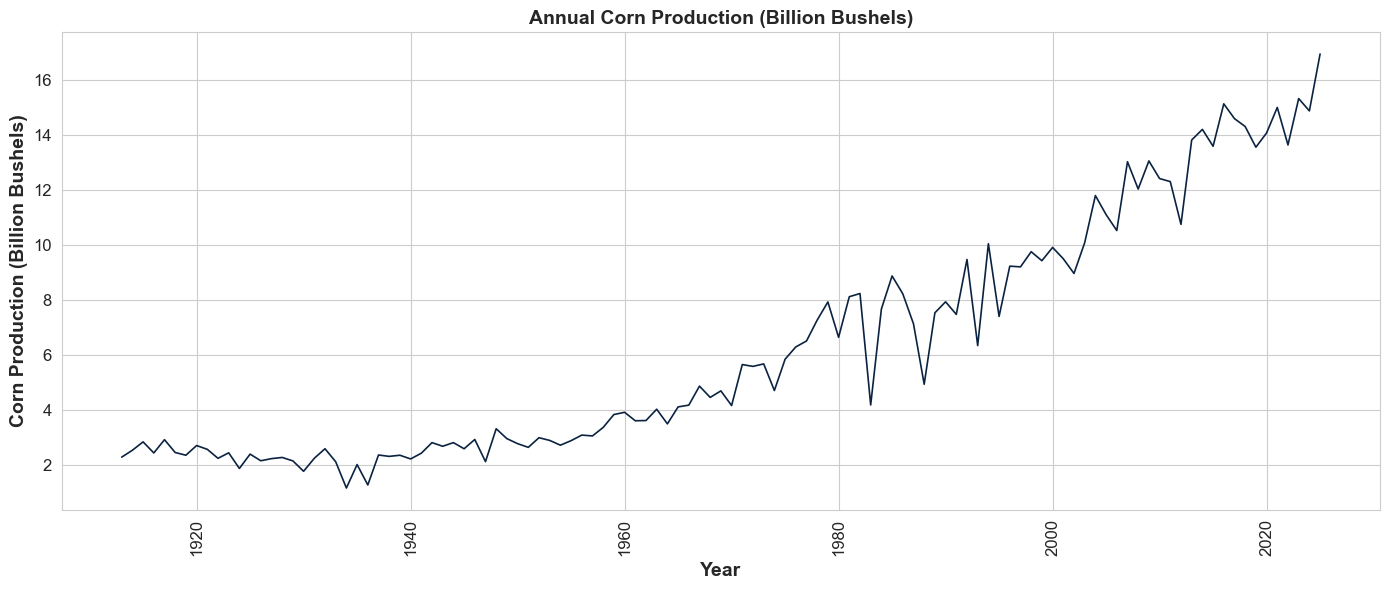

In [12]:
# Create a new figure; width=14in controls figure width, while height=6in controls figure height
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=corn,            # DataFrame containing the corn data
    x='year',             # Plot year on the x-axis
    y='production_billion_bu',    # Plot corn production on the y-axis
    linewidth=1.2,        # Increase for thicker lines
    color='#0b2341'       # Line color
)

# Plot title
plt.title("Annual Corn Production (Billion Bushels)", fontsize=14, weight='bold')

# X and Y axis labels
plt.xlabel("Year", fontsize=14, weight='bold')
plt.ylabel("Corn Production (Billion Bushels)", fontsize=14, weight='bold')

# Rotate year labels 90 degrees so they don't overlap; ha='center' aligns them under their tick marks
plt.xticks(rotation=90, ha='center', fontsize=12)
plt.yticks(fontsize=12)

# Automatically adjust margins so rotated x-labels are not clipped
plt.tight_layout()

plt.show()  # Render the figure inline in the notebook

#### Nominal Prices

Visualize nominal prices ($ / bushel) over time

Documentation: [Seaborn Line Plot](https://seaborn.pydata.org/generated/seaborn.lineplot.html)

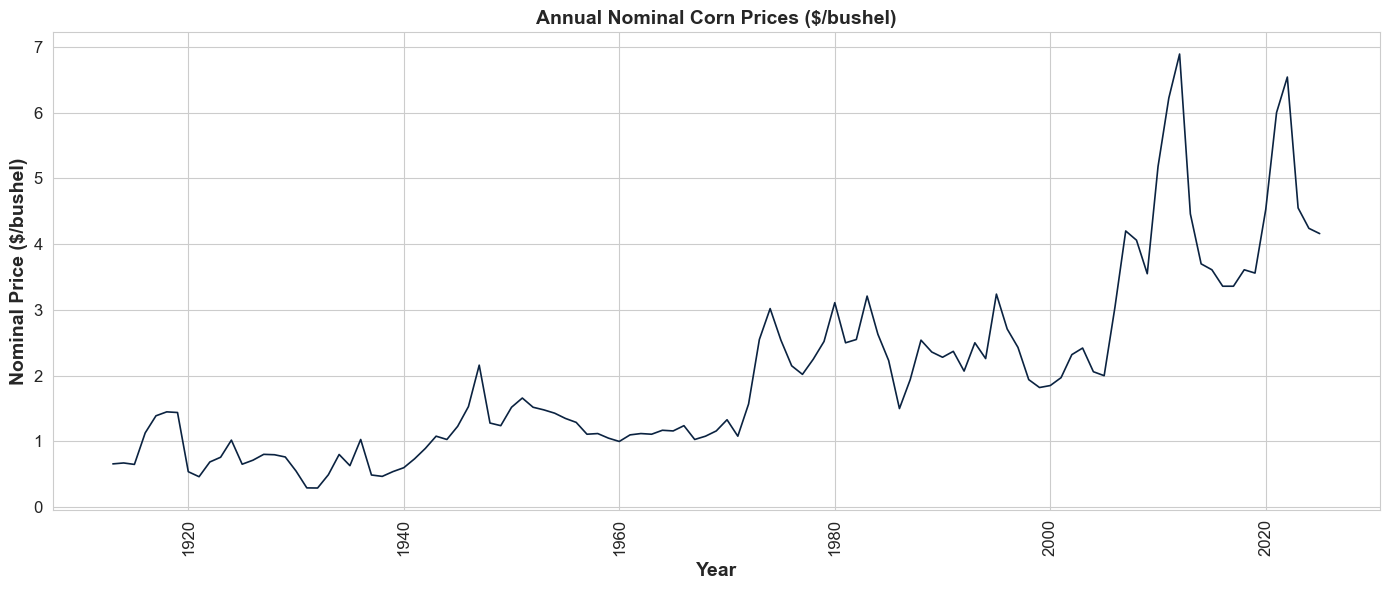

In [13]:
plt.figure(figsize=(14, 6))  # Same dimensions as the production chart so the plots are visually comparable

sns.lineplot(
    data=corn,            # DataFrame containing the corn data
    x='year',             # Plot year on the x-axis
    y='nominal_price',    # Plot nominal prices on the y-axis
    linewidth=1.2,        # Increase for thicker lines
    color='#0b2341'       # Line color
)

# Plot title
plt.title("Annual Nominal Corn Prices ($/bushel)", fontsize=14, weight='bold')

# X and Y axis labels
plt.xlabel("Year", fontsize=14, weight='bold')
plt.ylabel("Nominal Price ($/bushel)", fontsize=14, weight='bold')

# Rotate year labels 90 degrees so they don't overlap; ha='center' aligns them under their tick marks
plt.xticks(rotation=90, ha='center', fontsize=12)
plt.yticks(fontsize=12)

# Automatically adjust margins so rotated x-labels are not clipped
plt.tight_layout()

plt.show()  # Render the figure inline in the notebook

#### Real Prices

Now, we will recreate the line plot using real corn prices. The inflation-adjusted prices remove the effect of general price-level changes, allowing us to compare prices over time.

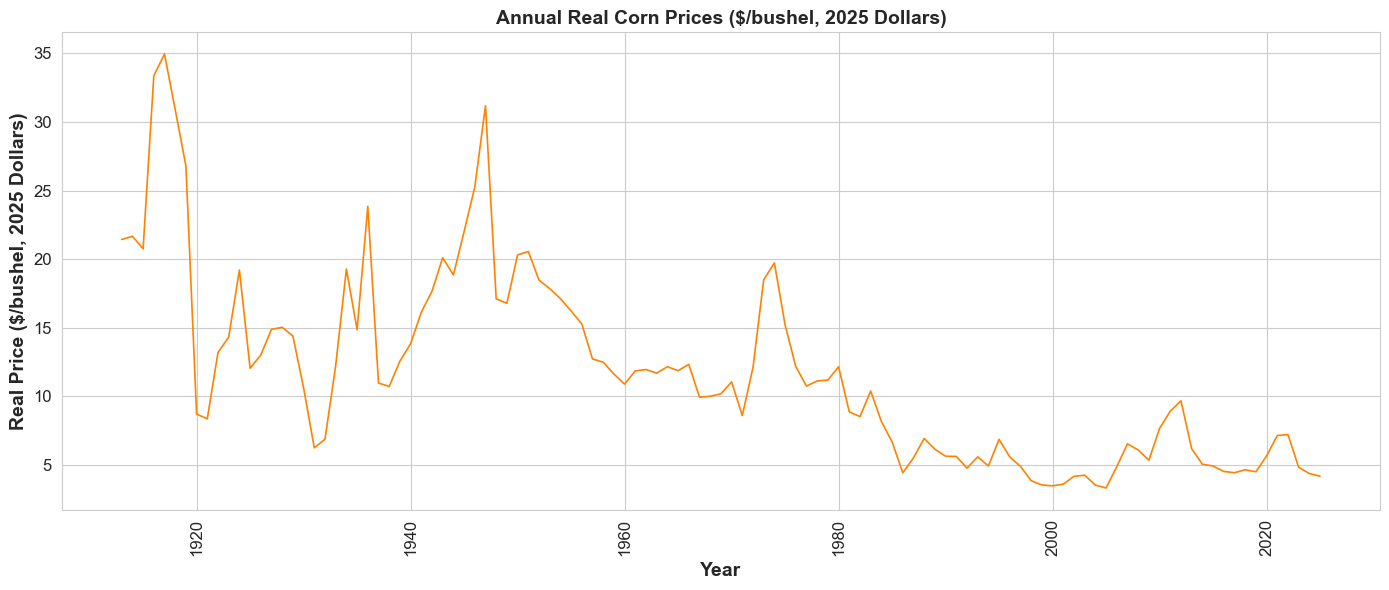

In [14]:
plt.figure(figsize=(14, 6))  # Same dimensions as the nominal price chart so the two are visually comparable

sns.lineplot(
    data=corn,            # DataFrame containing the corn data
    x='year',             # Plot year on the x-axis
    y='real_price',    # Plot the CPI-adjusted price (2025 dollars) on the y-axis
    linewidth=1.2,        # Increase for thicker lines
    color='#FF8200'       # Line color
)

# Plot title
plt.title("Annual Real Corn Prices ($/bushel, 2025 Dollars)", fontsize=14, weight='bold')

# X and Y axis labels
plt.xlabel("Year", fontsize=14, weight='bold')
plt.ylabel("Real Price ($/bushel, 2025 Dollars)", fontsize=14, weight='bold')

# Rotate year labels 90 degrees so they don't overlap; ha='center' aligns them under their tick marks
plt.xticks(rotation=90, ha='center', fontsize=12)
plt.yticks(fontsize=12)

# Automatically adjust margins so rotated x-labels are not clipped
plt.tight_layout()

plt.show()  # Render the figure inline in the notebook

#### Change in Prices

Year-over-year percentage changes show the volatility and direction of price movements more clearly than level plots.

- Large positive values indicate price spikes.
- Large negative values indicate sharp declines.
- Visualizing changes in prices over time is useful for identifying years when markets were particularly affected by market shocks (weather, policy, or global events).

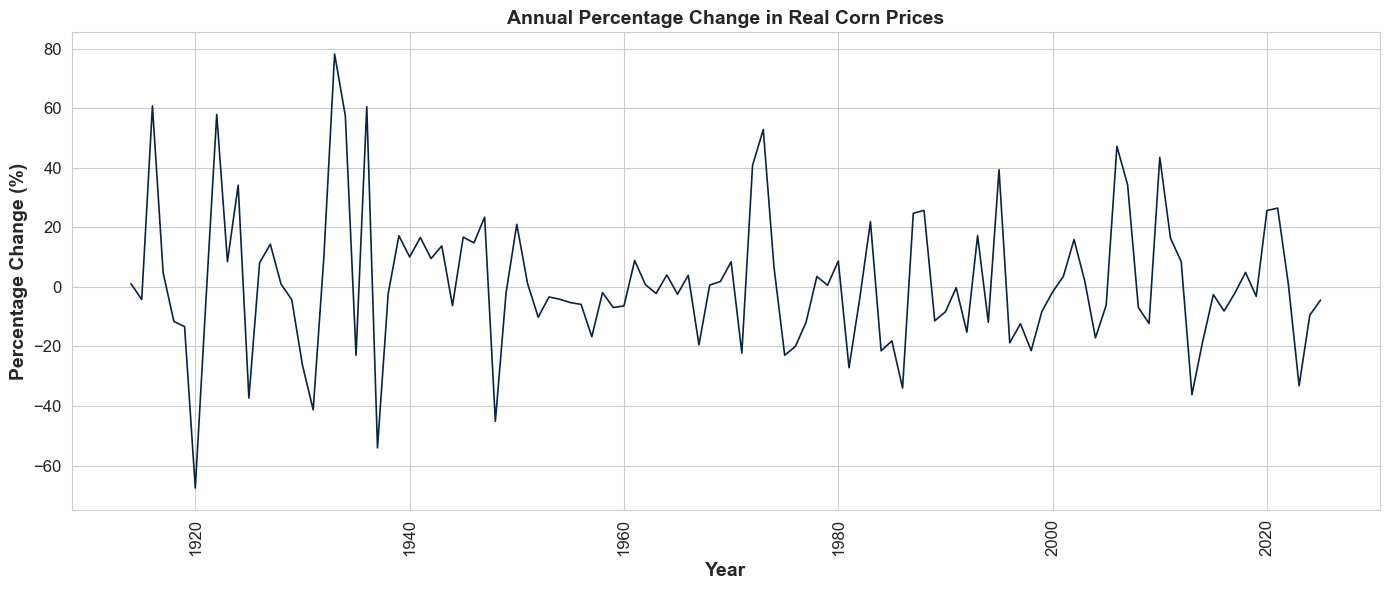

In [15]:
plt.figure(figsize=(14, 6))  # Wide figure accommodates several decades of annual data points without crowding

sns.lineplot(
    data=corn,            # DataFrame containing the corn data
    x='year',             # Plot year on the x-axis
    y='pct_change_real_price',    # Year-over-year percentage change in real prices; positive = prices rose, negative = fell
    linewidth=1.2,        # Increase for thicker lines
    color='#0b2341'       # Line color
)

# Plot title
plt.title("Annual Percentage Change in Real Corn Prices", fontsize=14, weight='bold')

# X and Y axis labels
plt.xlabel("Year", fontsize=14, weight='bold')
plt.ylabel("Percentage Change (%)", fontsize=14, weight='bold')

# Rotate year labels 90 degrees so they don't overlap; ha='center' aligns them under their tick marks
plt.xticks(rotation=90, ha='center', fontsize=12)
plt.yticks(fontsize=12)

# Automatically adjust margins so rotated x-labels are not clipped
plt.tight_layout()

plt.show()  # Render the figure inline in the notebook

## Interpreting the Graphs

Use your DataFrame to compute the values below. Each answer is stored in a variable. The cell prints it. You will be asked to do similar work in Homework 1.

In [16]:
# Year with the highest corn production
# idxmax() returns the row label of the largest value; .loc then looks up the year in that row
peak_production_year = corn.loc[corn['production_billion_bu'].idxmax(), 'year']
print(f"Corn production peaked in {peak_production_year}.")

Corn production peaked in 2025.


In [17]:
# Year with the largest year-to-year drop in real prices (the most negative year-over-year percentage change)
# idxmin() returns the row label of the smallest value
largest_drop_year = corn.loc[corn['pct_change_real_price'].idxmin(), 'year']
print(f"The largest year-to-year drop in real prices was in {largest_drop_year}.")

The largest year-to-year drop in real prices was in 1920.


In [18]:
# Percentage change from 1913 to 2025 = (end - start) / start * 100
# .iloc[0] selects the first row (1913) and .iloc[-1] selects the last row (2025)
nominal_start = corn['nominal_price'].iloc[0]
nominal_end = corn['nominal_price'].iloc[-1]
nominal_change = (nominal_end - nominal_start) / nominal_start * 100

# The same formula with the real price
real_start = corn['real_price'].iloc[0]
real_end = corn['real_price'].iloc[-1]
real_change = (real_end - real_start) / real_start * 100

print(f"Nominal price change, 1913 to 2025: {nominal_change:.1f}%")
print(f"Real price change, 1913 to 2025: {real_change:.1f}%")

Nominal price change, 1913 to 2025: 531.3%
Real price change, 1913 to 2025: -80.6%


In [19]:
# Volatility is the standard deviation of the year-over-year percentage changes
price_volatility = corn['pct_change_real_price'].std()
cpi_volatility = corn['annual_avg_cpi'].pct_change().std() * 100

print(f"Standard deviation of year-over-year changes in the real corn price: {price_volatility:.1f} percentage points")
print(f"Standard deviation of year-over-year changes in the CPI (the general price level): {cpi_volatility:.1f} percentage points")

Standard deviation of year-over-year changes in the real corn price: 24.1 percentage points
Standard deviation of year-over-year changes in the CPI (the general price level): 4.6 percentage points


### Summary of Answers

Run the cell below to print the answers in one table.

In [20]:
# Collect the answers computed above in one table
summary = pd.Series({
    'Base-year CPI': cpi_base_year,
    'Year of peak production': peak_production_year,
    'Year of largest year-to-year drop in real prices': largest_drop_year,
    'Nominal price change, 1913 to 2025 (%)': round(nominal_change, 1),
    'Real price change, 1913 to 2025 (%)': round(real_change, 1),
    'Volatility of the real price (percentage points)': round(price_volatility, 1),
    'Volatility of the CPI (percentage points)': round(cpi_volatility, 1),
}, name='Answer', dtype=object)  # object type keeps years as whole numbers
summary.to_frame()

,Answer
Base-year CPI,321.943
Year of peak production,2025
Year of largest year-to-year drop in real prices,1920
"Nominal price change, 1913 to 2025 (%)",531.3
"Real price change, 1913 to 2025 (%)",-80.6
Volatility of the real price (percentage points),24.1
Volatility of the CPI (percentage points),4.6
